<a href="https://colab.research.google.com/github/kurusnyakapan-dotcom/Laporan-EDA-Penanggulangan-Bencana/blob/main/EDA_Bencana_Cilacap_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAPORAN EXPLORATORY DATA ANALYSIS (EDA)
**Studi Kasus:** Rekapitulasi Kejadian dan Dampak Bencana di Kabupaten Cilacap (Januari – Agustus 2026)

Notebook ini disusun mengikuti struktur standar Bab 1 hingga Bab 9 untuk tugas UTS Data Science.

## Bab 3: Memuat & Memeriksa Data (Importing and Inspecting the Data)

In [1]:
# 3.1 Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# Membuat dataset langsung di dalam notebook agar mandiri (self-contained)
# Anda juga bisa menggantinya dengan: df_raw = pd.read_csv('dataset_bencana_cilacap_2026.csv')
data_rows = [
    ['BANJIR'] + ['-']*37 + ['Rp0'],
    ['TNH.LONGSOR', 33, 19, 32, '-', '-', '-', '-', 2, 18, 8, '-', 32, 2, '-', 2, 6, 14, 6, 4, 8, '-', '-', '-', 1, '-', '-', '-', 1, 2, 73, 31, 36, 47, 11, 3, 3, 8, 'Rp1.550.900.000'],
    ['CUACA EKSTREM', 93, 51, 83, '-', '-', '-', 7, 23, 37, 802, '-', '-', 2, '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', 21, '-', 4, 2679, 851, 1188, 1499, 13, 7, 5, 8, 'Rp1.423.925.000'],
    ['KEKERINGAN', 61, 32, 59, '-', '-', '-', '-', '-', '-', '-', '-', 41116, 57, '-', '-', '-', '-', '-', 77, '-', '-', 2, '-', '-', 1, '-', '-', '-', 9, 41332, 14821, 17119, 22988, '-', '-', '-', '-', 'Rp0'],
    ['KARHUTLA', 8, 7, 8, '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', 6, '-', '-', '-', '-', '-', '-', 214, 64, '-', '-', '-', '-', '-', '-', 'Rp1.350.000'],
    ['GEL.PASANG & ABRASI'] + ['-']*37 + ['Rp0'],
    ['KEKERINGAN'] + ['-']*37 + ['Rp0'],
    ['GEMPA BUMI'] + ['-']*37 + ['Rp0'],
    ['TSUNAMI'] + ['-']*37 + ['Rp0'],
    ['ERUPSI GUNUNG API'] + ['-']*37 + ['Rp0'],
    ['EPIDEMI DAN WABAH PENYAKIT'] + ['-']*37 + ['Rp0'],
    ['KEBAKARAN GEDUNG DAN PEMUKIMAN', 6, 6, 6, '-', '-', '-', 1, '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', 3, '-', '-', '-', '-', '-', '-', 287, 75, '-', '-', '-', '-', '-', '-', 'Rp20.000.000'],
    ['GAGAL TEKNOLOGI'] + ['-']*37 + ['Rp0'],
    ['KONFLIK SOSIAL'] + ['-']*37 + ['Rp0'],
    ['KEJADIAN LAINNYA', 9, 6, 9, 5, '-', '-', 2, '-', 1, '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', '-', 6, 4, 4, 4, 1, 1, 1, '-', 'Rp118.500.000']
]

columns = [
    'Jenis_Bencana', 'Kejadian', 'Kecamatan_Terdampak', 'Desa_Kelurahan_Terdampak',
    'Meninggal_Dunia', 'Luka_Berat', 'Luka_Ringan',
    'Rumah_Roboh_Musnah', 'Rumah_Rusak_Berat', 'Rumah_Rusak_Sedang', 'Rumah_Rusak_Ringan',
    'Rumah_Terendam_KK', 'Rumah_Terancam',
    'Infra_Sekolah', 'Infra_Jln_Nas', 'Infra_Jln_Prov', 'Infra_Jln_Kab', 'Infra_Jln_Desa',
    'Infra_Tebing', 'Infra_Sawah', 'Infra_Turap_Talud', 'Infra_Tanggul', 'Infra_Saluran_Air',
    'Infra_Lahan_Terbakar', 'Infra_Pabrik', 'Infra_Pasar', 'Infra_Tempat_Usaha',
    'Infra_Jembatan', 'Infra_Fasum_Lainnya',
    'Warga_Terdampak_Jiwa', 'Warga_Terdampak_KK', 'Warga_Terdampak_L', 'Warga_Terdampak_P',
    'Pengungsi_Jiwa', 'Pengungsi_KK', 'Pengungsi_L', 'Pengungsi_P',
    'Jumlah_Kerugian'
]

data_rows = [r[:len(columns)] for r in data_rows]
df_raw = pd.DataFrame(data_rows, columns=columns)
df_raw.to_csv('dataset_bencana_cilacap_2026.csv', index=False)

# 3.2 Inspeksi Dimensi & Struktur
print('Dimensi Dataset Awal:', df_raw.shape)
display(df_raw.head())

Dimensi Dataset Awal: (15, 38)


,Jenis_Bencana,Kejadian,Kecamatan_Terdampak,Desa_Kelurahan_Terdampak,Meninggal_Dunia,Luka_Berat,Luka_Ringan,Rumah_Roboh_Musnah,Rumah_Rusak_Berat,Rumah_Rusak_Sedang,...,Infra_Fasum_Lainnya,Warga_Terdampak_Jiwa,Warga_Terdampak_KK,Warga_Terdampak_L,Warga_Terdampak_P,Pengungsi_Jiwa,Pengungsi_KK,Pengungsi_L,Pengungsi_P,Jumlah_Kerugian
0,BANJIR,-,-,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,-
1,TNH.LONGSOR,33,19,32,-,-,-,-,2,18,...,1,2,73,31,36,47,11,3,3,8
2,CUACA EKSTREM,93,51,83,-,-,-,7,23,37,...,-,4,2679,851,1188,1499,13,7,5,8
3,KEKERINGAN,61,32,59,-,-,-,-,-,-,...,-,9,41332,14821,17119,22988,-,-,-,-
4,KARHUTLA,8,7,8,-,-,-,-,-,-,...,-,-,214,64,-,-,-,-,-,-


In [2]:
# 3.3 Pemeriksaan Tipe Data dan Informasi Umum
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 38 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Jenis_Bencana             15 non-null     object
 1   Kejadian                  15 non-null     object
 2   Kecamatan_Terdampak       15 non-null     object
 3   Desa_Kelurahan_Terdampak  15 non-null     object
 4   Meninggal_Dunia           15 non-null     object
 5   Luka_Berat                15 non-null     object
 6   Luka_Ringan               15 non-null     object
 7   Rumah_Roboh_Musnah        15 non-null     object
 8   Rumah_Rusak_Berat         15 non-null     object
 9   Rumah_Rusak_Sedang        15 non-null     object
 10  Rumah_Rusak_Ringan        15 non-null     object
 11  Rumah_Terendam_KK         15 non-null     object
 12  Rumah_Terancam            15 non-null     object
 13  Infra_Sekolah             15 non-null     object
 14  Infra_Jln_Nas             15

## Bab 4: Penanganan Data yang Hilang & Duplikat (Handling Missing Data)

In [3]:
# 4.1 Identifikasi Nilai Kosong ('-')
df = df_raw.replace('-', np.nan)
print('Jumlah Missing Values per Kolom Utama:')
print(df[['Jenis_Bencana', 'Kejadian', 'Warga_Terdampak_Jiwa', 'Jumlah_Kerugian']].isnull().sum())

# Cek duplikasi nama bencana
print('\nDuplikasi Jenis Bencana:', df['Jenis_Bencana'].value_counts()[df['Jenis_Bencana'].value_counts() > 1])

# 4.3 Strategi Eliminasi: Hapus baris duplikat KEKERINGAN yang kosong (index 6)
df = df.drop(index=6).reset_index(drop=True)

# 4.4 Strategi Imputasi: Bersihkan format Rp & konversi NaN menjadi 0
df['Jumlah_Kerugian'] = (
    df['Jumlah_Kerugian'].astype(str)
    .str.replace('Rp', '', regex=False)
    .str.replace('.', '', regex=False)
    .astype(float)
)

num_cols = [c for c in df.columns if c != 'Jenis_Bencana']
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

print('\nDimensi Dataset Setelah Pembersihan:', df.shape)
display(df[['Jenis_Bencana', 'Kejadian', 'Rumah_Rusak_Ringan', 'Warga_Terdampak_Jiwa', 'Jumlah_Kerugian']])

Jumlah Missing Values per Kolom Utama:
Jenis_Bencana            0
Kejadian                 9
Warga_Terdampak_Jiwa    12
Jumlah_Kerugian         13
dtype: int64

Duplikasi Jenis Bencana: Jenis_Bencana
KEKERINGAN    2
Name: count, dtype: int64

Dimensi Dataset Setelah Pembersihan: (14, 38)


/tmp/ipykernel_589/582383753.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df_raw.replace('-', np.nan)


,Jenis_Bencana,Kejadian,Rumah_Rusak_Ringan,Warga_Terdampak_Jiwa,Jumlah_Kerugian
0,BANJIR,0.0,0.0,0.0,0.0
1,TNH.LONGSOR,33.0,8.0,2.0,80.0
2,CUACA EKSTREM,93.0,802.0,4.0,80.0
3,KEKERINGAN,61.0,0.0,9.0,0.0
4,KARHUTLA,8.0,0.0,0.0,0.0
5,GEL.PASANG & ABRASI,0.0,0.0,0.0,0.0
6,GEMPA BUMI,0.0,0.0,0.0,0.0
7,TSUNAMI,0.0,0.0,0.0,0.0
8,ERUPSI GUNUNG API,0.0,0.0,0.0,0.0
9,EPIDEMI DAN WABAH PENYAKIT,0.0,0.0,0.0,0.0


## Bab 5: Eksplorasi Karakteristik Data (Exploring Data Characteristics)

In [4]:
# 5.1 Statistik Deskriptif Variabel Utama
main_vars = ['Kejadian', 'Rumah_Rusak_Ringan', 'Warga_Terdampak_Jiwa', 'Jumlah_Kerugian']
display(df[main_vars].describe())

# 5.2 Analisis Skewness & Kurtosis
skew_kurt = pd.DataFrame({
    'Skewness': df[main_vars].skew(),
    'Kurtosis': df[main_vars].kurt()
})
print('\nNilai Skewness dan Kurtosis:')
display(skew_kurt)

,Kejadian,Rumah_Rusak_Ringan,Warga_Terdampak_Jiwa,Jumlah_Kerugian
count,14.000000,14.000000,14.000000,14.000000
mean,15.000000,57.857143,1.071429,11.428571
std,28.406391,214.189656,2.555967,29.050922
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000
75%,8.750000,0.000000,0.000000,0.000000
max,93.000000,802.000000,9.000000,80.000000



Nilai Skewness dan Kurtosis:


,Skewness,Kurtosis
Kejadian,2.151143,4.055303
Rumah_Rusak_Ringan,3.741012,13.996528
Warga_Terdampak_Jiwa,2.745271,7.744508
Jumlah_Kerugian,2.294821,3.791667


## Bab 6: Transformasi Data & Feature Engineering

In [5]:
# 6.1 Log Transformation untuk memperbaiki skewness
df['Log_Kerugian'] = np.log1p(df['Jumlah_Kerugian'])
df['Log_Warga_Terdampak'] = np.log1p(df['Warga_Terdampak_Jiwa'])

# 6.2 Normalisasi MinMaxScaler (0 - 1)
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df[main_vars]), columns=[c + '_Scaled' for c in main_vars])

# 6.4 Feature Engineering: Kerugian Rata-rata per Kejadian & Total Rumah Rusak
df['Kerugian_Per_Kejadian'] = np.where(df['Kejadian'] > 0, df['Jumlah_Kerugian'] / df['Kejadian'], 0)
df['Total_Rumah_Rusak'] = (
    df['Rumah_Roboh_Musnah'] + df['Rumah_Rusak_Berat'] +
    df['Rumah_Rusak_Sedang'] + df['Rumah_Rusak_Ringan']
)

display(df[df['Kejadian'] > 0][['Jenis_Bencana', 'Kejadian', 'Total_Rumah_Rusak', 'Jumlah_Kerugian', 'Kerugian_Per_Kejadian']])

,Jenis_Bencana,Kejadian,Total_Rumah_Rusak,Jumlah_Kerugian,Kerugian_Per_Kejadian
1,TNH.LONGSOR,33.0,28.0,80.0,2.424242
2,CUACA EKSTREM,93.0,869.0,80.0,0.860215
3,KEKERINGAN,61.0,0.0,0.0,0.000000
4,KARHUTLA,8.0,0.0,0.0,0.000000
10,KEBAKARAN GEDUNG DAN PEMUKIMAN,6.0,1.0,0.0,0.000000
13,KEJADIAN LAINNYA,9.0,3.0,0.0,0.000000


## Bab 7 & 8: Visualisasi Hubungan Data & Deteksi Pencilan (Outliers)

/tmp/ipykernel_589/1699235345.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x='Kejadian', y='Jenis_Bencana', palette='viridis')


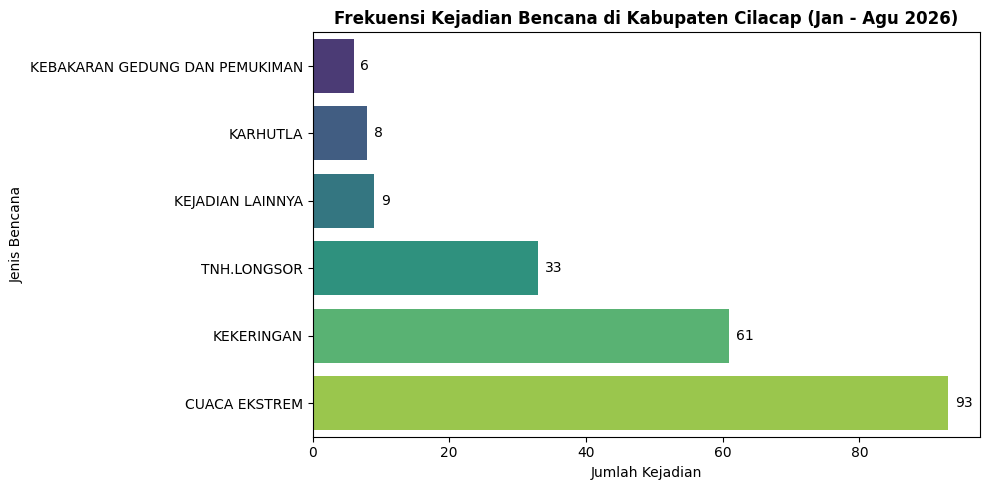

/tmp/ipykernel_589/1699235345.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_rugi, x='Kerugian_Juta', y='Jenis_Bencana', palette='magma')


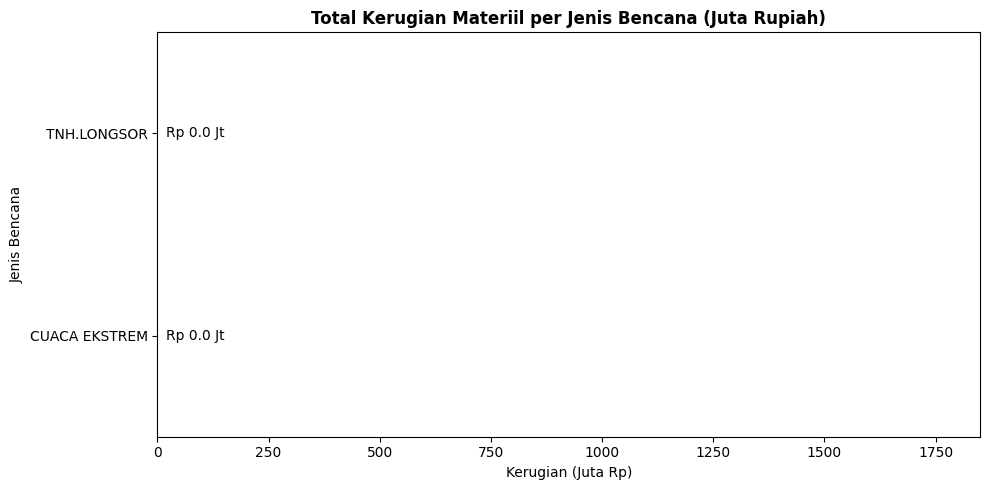

In [6]:
# 7.1 Bar Chart Frekuensi Kejadian Bencana
plt.figure(figsize=(10, 5))
df_plot = df[df['Kejadian'] > 0].sort_values('Kejadian', ascending=True)
sns.barplot(data=df_plot, x='Kejadian', y='Jenis_Bencana', palette='viridis')
plt.title('Frekuensi Kejadian Bencana di Kabupaten Cilacap (Jan - Agu 2026)', fontweight='bold')
plt.xlabel('Jumlah Kejadian')
plt.ylabel('Jenis Bencana')
for idx, val in enumerate(df_plot['Kejadian']):
    plt.text(val + 1, idx, f'{int(val)}', va='center')
plt.tight_layout()
plt.show()

# 7.1 Bar Chart Kerugian Materiil
plt.figure(figsize=(10, 5))
df_rugi = df[df['Jumlah_Kerugian'] > 0].copy()
df_rugi['Kerugian_Juta'] = df_rugi['Jumlah_Kerugian'] / 1e6
df_rugi = df_rugi.sort_values('Kerugian_Juta', ascending=True)
sns.barplot(data=df_rugi, x='Kerugian_Juta', y='Jenis_Bencana', palette='magma')
plt.title('Total Kerugian Materiil per Jenis Bencana (Juta Rupiah)', fontweight='bold')
plt.xlabel('Kerugian (Juta Rp)')
plt.ylabel('Jenis Bencana')
for idx, val in enumerate(df_rugi['Kerugian_Juta']):
    plt.text(val + 20, idx, f'Rp {val:,.1f} Jt', va='center')
plt.xlim(0, 1850)
plt.tight_layout()
plt.show()

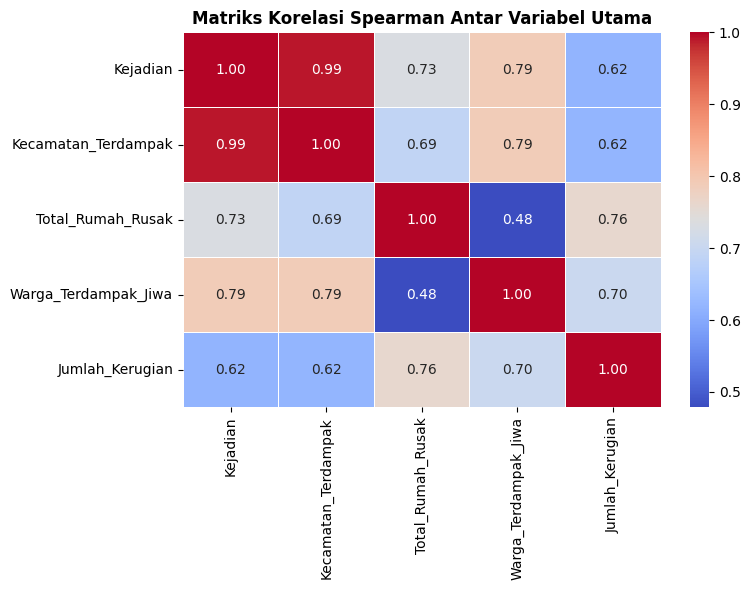

Outliers pada Kejadian (Batas Atas = 21.88):
Jenis_Bencana  Kejadian
  TNH.LONGSOR      33.0
CUACA EKSTREM      93.0
   KEKERINGAN      61.0 

Outliers pada Warga_Terdampak_Jiwa (Batas Atas = 0.00):
Jenis_Bencana  Warga_Terdampak_Jiwa
  TNH.LONGSOR                   2.0
CUACA EKSTREM                   4.0
   KEKERINGAN                   9.0 

Outliers pada Jumlah_Kerugian (Batas Atas = 0.00):
Jenis_Bencana  Jumlah_Kerugian
  TNH.LONGSOR             80.0
CUACA EKSTREM             80.0 



In [7]:
# 7.3 Heatmap Korelasi Spearman
plt.figure(figsize=(8, 6))
corr_vars = ['Kejadian', 'Kecamatan_Terdampak', 'Total_Rumah_Rusak', 'Warga_Terdampak_Jiwa', 'Jumlah_Kerugian']
sns.heatmap(df[corr_vars].corr(method='spearman'), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Spearman Antar Variabel Utama', fontweight='bold')
plt.tight_layout()
plt.show()

# 8.1 Deteksi Outliers dengan Metode IQR
for col in ['Kejadian', 'Warga_Terdampak_Jiwa', 'Jumlah_Kerugian']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[df[col] > upper_bound][['Jenis_Bencana', col]]
    print(f'Outliers pada {col} (Batas Atas = {upper_bound:,.2f}):')
    print(outliers.to_string(index=False), '\n')